# Pergunta 3: tratamento em até 60 dias × oferta de mamógrafos

**Pergunta:** como varia o tratamento em até 60 dias entre os estados, e como ele se relaciona com a oferta de mamógrafos?

Dados: `base_uf.csv` (já tratada no notebook `01_preparacao.ipynb`), com uma linha por UF.

## 0. Preparação do ambiente

In [26]:
!pip install -q geopandas

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110    # deixa os gráficos um pouco mais nítidos na tela
plt.rcParams["axes.spines.top"] = False     # tira a borda de cima do gráfico (visual mais limpo)
plt.rcParams["axes.spines.right"] = False   # tira a borda da direita do gráfico

## 1. Carregando os dados

No Colab, rode a célula abaixo e **selecione o arquivo `base_uf.csv`** (está em `dados/tratados/` do repositório).

In [25]:
CAMINHO = "base_uf.csv"

try:
    from google.colab import files  # só existe dentro do Google Colab
    import os
    if not os.path.exists(CAMINHO):
        files.upload()              # abre uma janelinha para você escolher o base_uf.csv
except ImportError:
    pass                            # se não estiver no Colab, não faz nada e usa o caminho acima

base = pd.read_csv(CAMINHO)         # lê o arquivo CSV e guarda na variável "base" (uma tabela)
base.head()                         # mostra as 5 primeiras linhas para conferir se carregou certo

,uf_sigla,uf_nome,cod_ibge,regiao,grupo_comparacao,incid_casos,incid_taxa_bruta,incid_taxa_ajustada,mort_obitos_2023,mort_taxa_bruta_2023,...,cobertura_pns_2013,cobertura_pns_2019,pct_tratados_ate_60_dias,exames_sus_2024,mamografos_existentes_2024,mamografos_em_uso_2024,pop_feminina_estimada,mamografos_por_100mil_mulheres,var_cobertura_2013_2019,razao_mortalidade_incidencia
0,AC,Acre,12,Norte,Norte/Nordeste,100,22.21,26.20,31,7.09,...,36.9,40.2,39.0,7649,26,25,450248,5.55,3.3,0.274
1,AM,Amazonas,13,Norte,Norte/Nordeste,500,22.77,28.34,253,12.00,...,52.4,51.5,34.1,20943,128,114,2195872,5.19,-0.9,0.432
2,AP,Amapá,16,Norte,Norte/Nordeste,80,16.58,20.04,26,6.51,...,38.0,34.9,30.6,3613,26,23,482509,4.77,-3.1,0.355
3,PA,Pará,15,Norte,Norte/Nordeste,1020,22.83,23.88,382,8.91,...,35.8,40.6,42.0,37334,201,189,4467806,4.23,4.8,0.339
4,RO,Rondônia,11,Norte,Norte/Nordeste,320,35.33,36.99,118,13.65,...,34.8,44.0,42.4,9274,67,61,905746,6.73,9.2,0.312


## 2. Escolhendo só as colunas da Pergunta 3

Das 21 colunas, a Pergunta 3 usa estas:

| Coluna | O que é |
|---|---|
| `uf_sigla`, `uf_nome` | identificam o estado |
| `regiao`, `grupo_comparacao` | para comparar regiões |
| `pct_tratados_ate_60_dias` | % dos casos que começaram o tratamento em até 60 dias (2020–2024) |
| `mamografos_em_uso_2024` | número de mamógrafos funcionando (dez/2024) |
| `mamografos_por_100mil_mulheres` | mamógrafos em uso ÷ população feminina × 100 mil (permite comparar estados de tamanhos diferentes) |

In [16]:
colunas = ["uf_sigla", "uf_nome", "regiao", "grupo_comparacao",
           "pct_tratados_ate_60_dias", "mamografos_em_uso_2024",
           "mamografos_por_100mil_mulheres"]          # lista das colunas que vamos usar
df = base[colunas].copy()                             # cria uma tabela nova só com essas colunas (.copy() evita mexer na original)

df = df.rename(columns={"pct_tratados_ate_60_dias": "pct_60dias",
                        "mamografos_por_100mil_mulheres": "mamog_100mil"})   # nomes mais curtos, para facilitar a digitação

print(df.shape)                                       # (linhas, colunas): esperado 27 linhas = 27 estados
print(df.isna().sum())                                # conta valores faltando em cada coluna: esperado tudo zero
print(df.dtypes)                                      # confere se os números estão como número (float/int) e não como texto

(27, 7)
uf_sigla                  0
uf_nome                   0
regiao                    0
grupo_comparacao          0
pct_60dias                0
mamografos_em_uso_2024    0
mamog_100mil              0
dtype: int64
uf_sigla                   object
uf_nome                    object
regiao                     object
grupo_comparacao           object
pct_60dias                float64
mamografos_em_uso_2024      int64
mamog_100mil              float64
dtype: object


In [17]:
# "Testes de segurança": se algo estiver errado, o código para aqui e avisa
assert len(df) == 27, "Deveria haver 27 UFs"                       # 26 estados + DF
assert df["uf_sigla"].is_unique, "Há UF repetida"                  # cada UF só pode aparecer uma vez
assert df["pct_60dias"].between(0, 100).all(), "Percentual fora de 0-100"   # porcentagem precisa estar entre 0 e 100
assert (df["mamog_100mil"] > 0).all(), "Mamógrafos por 100 mil deve ser positivo"
print("Dados conferidos: tudo certo!")

Dados conferidos: tudo certo!


## 3. Olhando os números (estatística descritiva)

In [18]:
print(df["pct_60dias"].describe().round(1))   # resumo: média, menor valor, maior valor, quartis

count    27.0
mean     42.0
std       7.2
min      30.6
25%      36.5
50%      42.6
75%      47.3
max      60.3
Name: pct_60dias, dtype: float64


In [19]:
# Ranking: quais estados têm os MENORES e os MAIORES percentuais de tratamento em até 60 dias?
ordenado = df.sort_values("pct_60dias")                              # ordena do menor para o maior
print("5 menores:\n", ordenado[["uf_sigla", "pct_60dias"]].head(5).to_string(index=False))   # as 5 primeiras linhas
print("\n5 maiores:\n", ordenado[["uf_sigla", "pct_60dias"]].tail(5).to_string(index=False)) # as 5 últimas linhas

5 menores:
 uf_sigla  pct_60dias
      AP        30.6
      DF        31.9
      PB        32.0
      AL        33.7
      AM        34.1

5 maiores:
 uf_sigla  pct_60dias
      MA        48.4
      SE        50.9
      PI        51.1
      ES        52.3
      PR        60.3


In [20]:
# Média por região: agrupa os estados da mesma região e tira a média
por_regiao = df.groupby("regiao")[["pct_60dias", "mamog_100mil"]].mean().round(1)   # média simples dos estados de cada região
por_regiao.sort_values("pct_60dias", ascending=False)                               # mostra da maior para a menor

,pct_60dias,mamog_100mil
regiao,,
Sul,49.2,6.5
Nordeste,43.5,7.5
Sudeste,43.0,6.5
Norte,38.5,5.0
Centro-Oeste,38.3,8.3


## 4. Gráfico 1: tratamento em até 60 dias, estado por estado

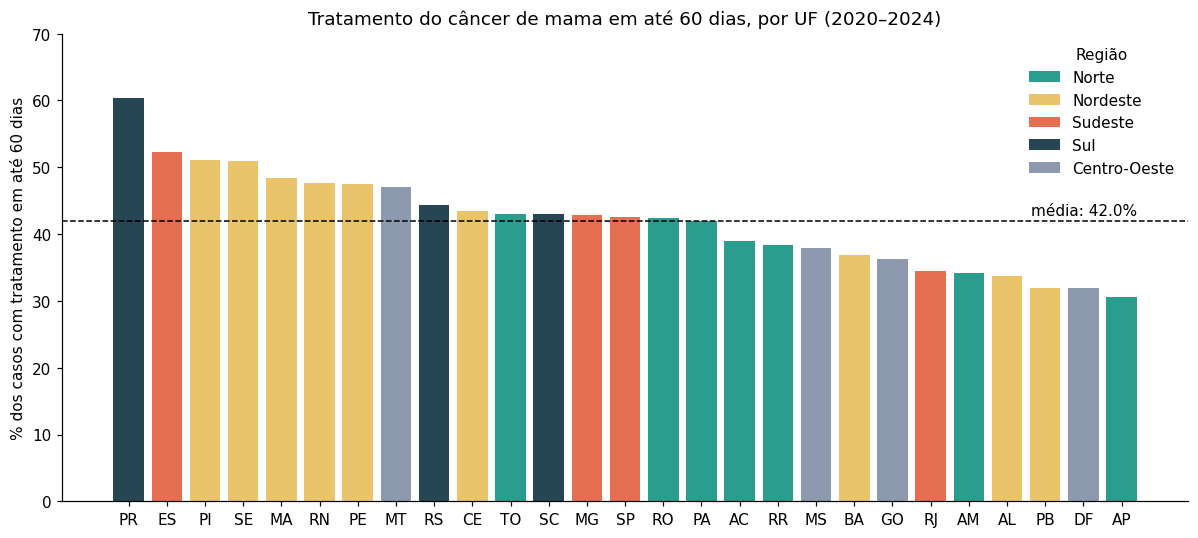

In [21]:
cores = {"Norte": "#2a9d8f", "Nordeste": "#e9c46a", "Sudeste": "#e76f51",
         "Sul": "#264653", "Centro-Oeste": "#8d99ae"}      # uma cor para cada região

d = df.sort_values("pct_60dias", ascending=False)           # ordena do maior para o menor (fica mais fácil de ler)
media = df["pct_60dias"].mean()                             # média simples dos 27 estados

fig, ax = plt.subplots(figsize=(11, 5))                     # cria a "folha" do gráfico (largura 11, altura 5)
ax.bar(d["uf_sigla"], d["pct_60dias"],
       color=d["regiao"].map(cores))                        # desenha as barras, pintando cada uma pela cor da sua região
ax.axhline(media, color="black", linestyle="--", linewidth=1)   # linha tracejada na média
ax.text(26.4, media + 0.8, f"média: {media:.1f}%", ha="right")  # escreve o valor da média ao lado da linha

for regiao, cor in cores.items():                           # cria a legenda manualmente, uma entrada por região
    ax.bar(0, 0, color=cor, label=regiao)                   # barra "invisível" só para aparecer na legenda
ax.legend(title="Região", frameon=False)                    # mostra a legenda sem moldura

ax.set_ylim(0, 70)                                          # eixo Y começa no ZERO (importante para não distorcer!)
ax.set_ylabel("% dos casos com tratamento em até 60 dias")  # texto do eixo vertical
ax.set_title("Tratamento do câncer de mama em até 60 dias, por UF (2020–2024)")   # título
plt.tight_layout()                                          # ajusta margens para nada ficar cortado
plt.show()                                                  # exibe o gráfico

## 5. Gráfico 2: mamógrafos × tratamento em até 60 dias

Se ter mais mamógrafos ajudasse a tratar mais rápido, esperaríamos ver os pontos subindo da esquerda para a direita.
A **correlação de Spearman** (ρ, "rô") resume isso: vai de −1 a +1; perto de 0 significa "uma coisa não acompanha a outra".

Correlação de Spearman: -0.11


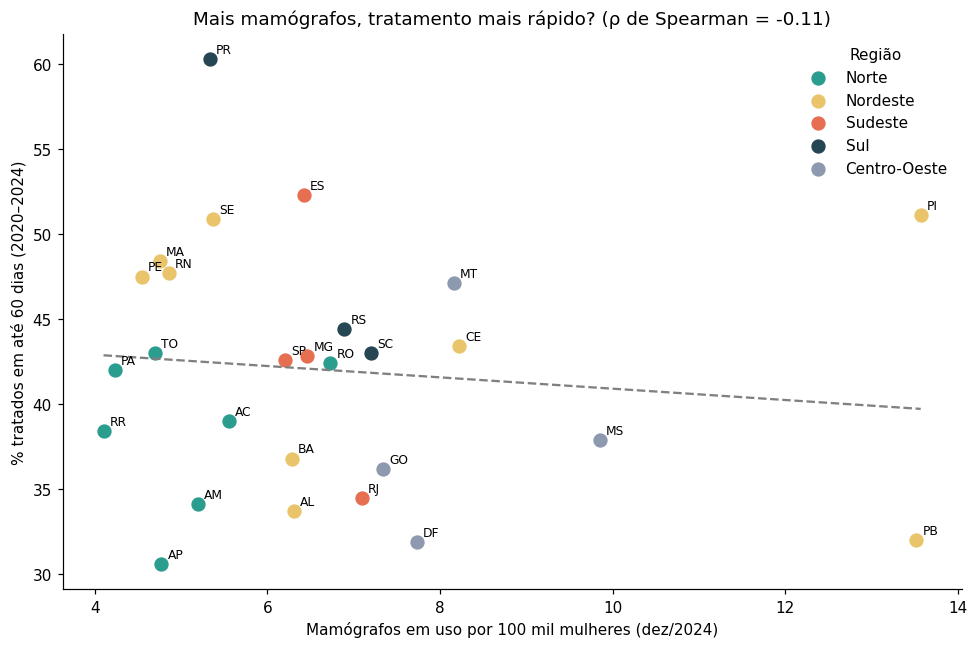

In [22]:
rho = df["mamog_100mil"].corr(df["pct_60dias"], method="spearman")   # correlação de Spearman entre as duas colunas
print(f"Correlação de Spearman: {rho:.2f}")                         # mostra o valor

fig, ax = plt.subplots(figsize=(9, 6))                      # cria a folha do gráfico
for regiao, cor in cores.items():                           # desenha uma região por vez, para colorir
    sub = df[df["regiao"] == regiao]                        # filtra só os estados dessa região
    ax.scatter(sub["mamog_100mil"], sub["pct_60dias"],
               s=70, color=cor, label=regiao)               # um ponto por estado (s = tamanho do ponto)

for _, linha in df.iterrows():                              # percorre cada estado para escrever a sigla ao lado do ponto
    ax.annotate(linha["uf_sigla"],
                (linha["mamog_100mil"], linha["pct_60dias"]),
                xytext=(4, 4), textcoords="offset points", fontsize=8)   # desloca o texto 4 pontos para não cobrir o ponto

a, b = np.polyfit(df["mamog_100mil"], df["pct_60dias"], 1)  # calcula a reta que melhor resume os pontos (inclinação a, altura b)
xs = np.linspace(df["mamog_100mil"].min(), df["mamog_100mil"].max(), 50)   # 50 valores entre o menor e o maior x
ax.plot(xs, a * xs + b, color="gray", linestyle="--")       # desenha a linha de tendência

ax.set_xlabel("Mamógrafos em uso por 100 mil mulheres (dez/2024)")   # texto do eixo X
ax.set_ylabel("% tratados em até 60 dias (2020–2024)")               # texto do eixo Y
ax.set_title(f"Mais mamógrafos, tratamento mais rápido? (ρ de Spearman = {rho:.2f})")   # título com a correlação
ax.legend(title="Região", frameon=False)                    # legenda das cores
plt.tight_layout()                                          # ajusta margens
plt.show()                                                  # exibe

## 6. Mapa do Brasil

['codarea', 'geometry']


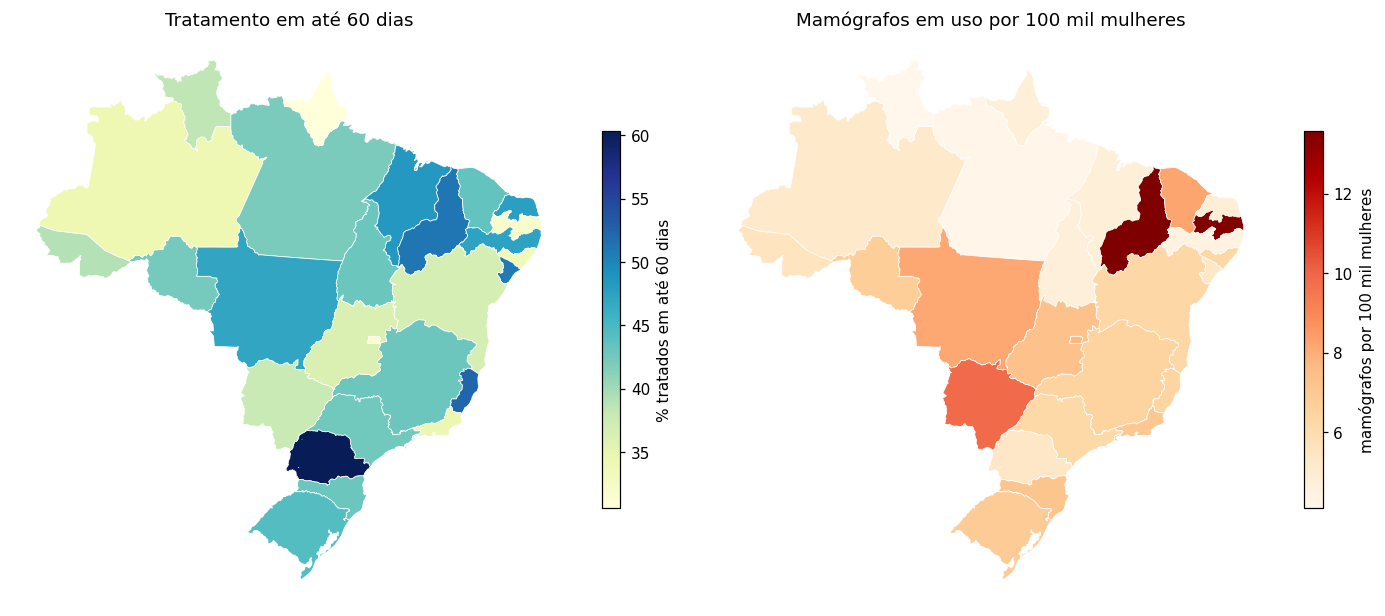

In [23]:
import geopandas as gpd                                     # geopandas: lê e desenha mapas (já vem instalado no Colab)

URL_IBGE = ("https://servicodados.ibge.gov.br/api/v3/malhas/paises/BR"
            "?intrarregiao=UF&formato=application/vnd.geo+json&qualidade=minima")   # endereço do IBGE com o desenho dos 27 estados
estados = gpd.read_file(URL_IBGE)                           # baixa o desenho (polígono) de cada estado
print(estados.columns.tolist())                             # mostra as colunas do mapa; deve aparecer "codarea" (código IBGE do estado)

estados["cod_ibge"] = estados["codarea"].astype(int)        # transforma o código do estado em número inteiro
codigos = base[["uf_sigla", "cod_ibge"]]                    # pega da base original a ligação sigla <-> código IBGE
dados_mapa = df.merge(codigos, on="uf_sigla")               # acrescenta o código IBGE na nossa tabela da Pergunta 3
mapa = estados.merge(dados_mapa, on="cod_ibge", how="left") # cola nossos dados em cada estado, usando o código como "chave"
assert mapa["pct_60dias"].notna().all(), "Algum estado ficou sem dados"     # confere que os 27 estados casaram

fig, eixos = plt.subplots(1, 2, figsize=(13, 6))            # duas figuras lado a lado: mapa 1 e mapa 2

mapa.plot(column="pct_60dias", cmap="YlGnBu", legend=True, ax=eixos[0],
          edgecolor="white", linewidth=0.5,
          legend_kwds={"label": "% tratados em até 60 dias", "shrink": 0.6})     # mapa 1: pinta cada estado conforme o % de tratamento
eixos[0].set_title("Tratamento em até 60 dias")             # título do mapa 1

mapa.plot(column="mamog_100mil", cmap="OrRd", legend=True, ax=eixos[1],
          edgecolor="white", linewidth=0.5,
          legend_kwds={"label": "mamógrafos por 100 mil mulheres", "shrink": 0.6})   # mapa 2: pinta conforme a oferta de mamógrafos
eixos[1].set_title("Mamógrafos em uso por 100 mil mulheres")   # título do mapa 2

for ax in eixos:                                            # para cada um dos dois mapas...
    ax.axis("off")                                          # ...remove os eixos (latitude/longitude não ajudam aqui)
plt.tight_layout()                                          # ajusta margens
plt.show()                                                  # exibe

## 7. Visualização enganosa (parte da tarefa da Pessoa 4)

Mesmos dados, dois gráficos. O da esquerda **corta o eixo Y** e exagera a diferença; o da direita começa no zero.

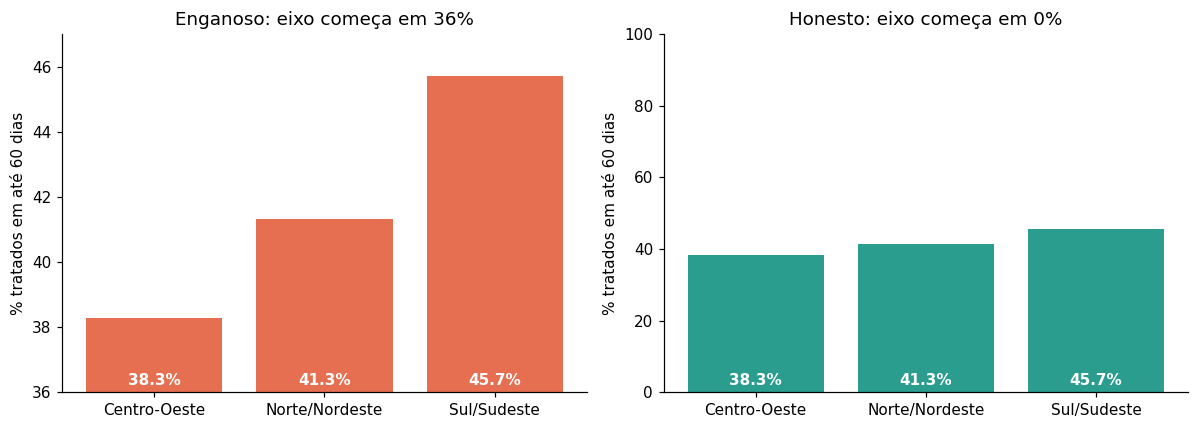

In [28]:
medias = df.groupby("grupo_comparacao")["pct_60dias"].mean().sort_values()   # média de cada grupo de regiões, do menor ao maior

fig, eixos = plt.subplots(1, 2, figsize=(11, 4))            # dois gráficos lado a lado

eixos[0].bar(medias.index, medias.values, color="#e76f51")  # gráfico 1: barras
eixos[0].set_ylim(36, 47)                                   # EIXO CORTADO: começa em 36, não em 0 (isso engana!)
eixos[0].set_title("Enganoso: eixo começa em 36%")          # título explicando o truque

eixos[1].bar(medias.index, medias.values, color="#2a9d8f")  # gráfico 2: mesmas barras
eixos[1].set_ylim(0, 100)                                   # EIXO HONESTO: de 0 a 100%
eixos[1].set_title("Honesto: eixo começa em 0%")            # título

for ax in eixos:                                            # nos dois gráficos...
    ax.set_ylabel("% tratados em até 60 dias")              # ...escreve o rótulo do eixo Y
    for i, v in enumerate(medias.values):                   # ...e escreve o valor em cima de cada barra
        ax.text(i, ax.get_ylim()[0] + (ax.get_ylim()[1] - ax.get_ylim()[0]) * 0.02, f"{v:.1f}%",
                ha="center", color="white", fontweight="bold")
plt.tight_layout()                                          # ajusta margens
plt.show()                                                  # exibe

## 8. Interpretação dos resultados

*(Os números abaixo vêm da execução com a `base_uf.csv` atual; se os dados mudarem, confira de novo.)*

**Como o tratamento em até 60 dias varia?** Bastante. Em média, cerca de 42% dos casos começam o tratamento em até 60 dias, mas o intervalo vai de 30,6% (Amapá) a 60,3% (Paraná). Os menores valores estão em Amapá, Distrito Federal, Paraíba, Alagoas e Amazonas; os maiores, em Paraná, Espírito Santo, Piauí, Sergipe e Maranhão. Por região, o Sul tem a maior média (cerca de 49%) e Centro-Oeste e Norte têm as menores (cerca de 38%).

**E os mamógrafos?** A correlação entre mamógrafos por 100 mil mulheres e o tratamento em até 60 dias é de cerca de **−0,11**, ou seja, praticamente zero. Estados com mais aparelhos não tratam mais rápido. Paraíba e Piauí têm a maior oferta (cerca de 13,5 por 100 mil), mas ficam em posições opostas: a Paraíba tem um dos piores índices de tratamento (32%) e o Piauí um dos melhores (51%).

**O que isso quer dizer?** Ter o aparelho é necessário para *diagnosticar*, mas o tempo até o *tratamento* depende de outras etapas: biópsia, laudo, encaminhamento, vaga em hospital oncológico, cirurgia, radioterapia. Os dados não mostram esses gargalos, então eles são uma hipótese, não um resultado.

**Limitações :**
- São apenas **27 pontos** (um por UF), e o resultado pode mudar com poucos estados.
- **Correlação não é causa**: mesmo se houvesse relação, não provaria que um fator causa o outro.
- Os **períodos são diferentes**: tratamento acumulado de 2020 a 2024 e mamógrafos em dezembro de 2024.
- O Painel-Oncologia **exclui casos sem informação de tratamento** e usa o estado de residência, e estados com registros piores podem parecer melhores ou piores sem que isso reflita a realidade.
- Os mamógrafos por 100 mil mulheres usam a população feminina de **todas as idades** (não só 50–69 anos) e o total do CNES, que inclui equipamentos privados.
- A média por região é uma média simples dos estados, **sem ponderar** pelo tamanho de cada um.